# Logistic Regression for Multinomial Classification

Step-by-step practical using the **Iris dataset**.

### Goals
- Understand multi-class classification
- Train Multinomial Logistic Regression
- Use `predict_proba()`
- Evaluate accuracy and confusion matrix
- Predict a new sample

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

## 2. Load the Iris Dataset

Iris has 4 input features and 3 classes:

```text
Setosa
Versicolor
Virginica
```

Therefore, this is a **multinomial classification problem**.

In [2]:
iris = load_iris()

X = iris.data
y = iris.target

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Classes:", iris.target_names)

X shape: (150, 4)
y shape: (150,)
Classes: ['setosa' 'versicolor' 'virginica']


## 3. Create a DataFrame

In [17]:
df = pd.DataFrame(X, columns=iris.feature_names)
df["target"] = y

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## 4. Visualize the Classes

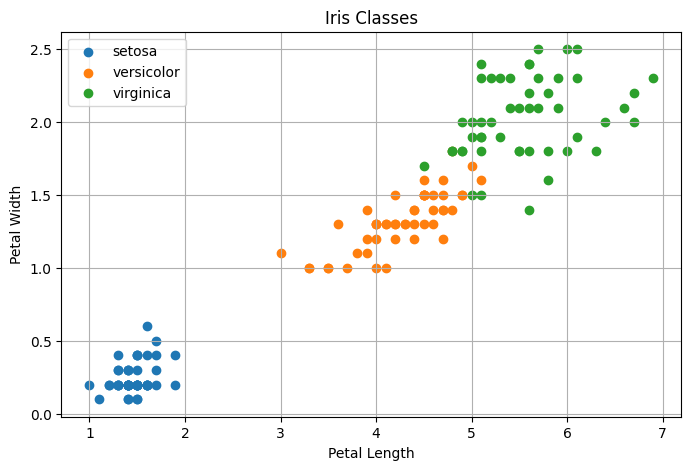

In [4]:
plt.figure(figsize=(8, 5))

for class_id, class_name in enumerate(iris.target_names):
    data = X[y == class_id]
    plt.scatter(data[:, 2], data[:, 3], label=class_name)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("Iris Classes")
plt.legend()
plt.grid(True)
plt.show()

## 5. Train/Test Split

Use 80% for training and 20% for testing.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (120, 4)
Testing : (30, 4)


## 6. Feature Scaling

Scale the features before training.

In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled[:2])

[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]]


# Part A — Multinomial Logistic Regression

## 7. Create and Train the Model

`multi_class="multinomial"` tells Logistic Regression to use the multinomial formulation for multiple classes.

In [7]:
model = LogisticRegression(
    multi_class="multinomial",
    max_iter=1000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("Model trained successfully!")

Model trained successfully!


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


## 8. Make Predictions

In [8]:
y_pred = model.predict(X_test_scaled)

print("Predictions:")
print(y_pred)

Predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


## 9. Actual vs Predicted

In [9]:
comparison = pd.DataFrame({
    "Actual": iris.target_names[y_test],
    "Predicted": iris.target_names[y_pred]
})

comparison.head(15)

,Actual,Predicted
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


# Part B — Class Probabilities

## 10. `predict_proba()`

For each sample, Logistic Regression gives a probability for every class.

The class with the highest probability becomes the prediction.

In [10]:
probabilities = model.predict_proba(X_test_scaled)

probability_df = pd.DataFrame(
    probabilities,
    columns=iris.target_names
)

probability_df.head()

,setosa,versicolor,virginica
0,0.978818,0.021182,3.638218e-07
1,0.003798,0.369220,6.269815e-01
2,0.148799,0.842475,8.726064e-03
3,0.095445,0.894619,9.936370e-03
4,0.988493,0.011507,1.725496e-07


## 11. Inspect One Prediction

In [11]:
i = 0

print("Actual:", iris.target_names[y_test[i]])

for name, p in zip(iris.target_names, probabilities[i]):
    print(f"{name}: {p:.4f}")

print("Predicted:", iris.target_names[y_pred[i]])

Actual: setosa
setosa: 0.9788
versicolor: 0.0212
virginica: 0.0000
Predicted: setosa


# Part C — Model Evaluation

## 12. Accuracy

In [12]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", round(accuracy, 4))

Accuracy: 0.9333


# Part D — Predict a New Flower

## 13. New Sample

Measurements:

```text
Sepal Length = 5.8
Sepal Width  = 3.0
Petal Length = 4.2
Petal Width  = 1.2
```

In [15]:
new_flower = np.array([[5.8, 3.0, 4.2, 1.2]])

new_scaled = scaler.transform(new_flower)

prediction = model.predict(new_scaled)
probability = model.predict_proba(new_scaled)

print("Predicted class:", iris.target_names[prediction[0]])

print("\nProbabilities:")
for name, p in zip(iris.target_names, probability[0]):
    print(f"{name}: {p:.4f}")

Predicted class: versicolor

Probabilities:
setosa: 0.0620
versicolor: 0.8919
virginica: 0.0461


# 14. How Multinomial Logistic Regression Works

```text
Input Features
      ↓
Logistic Regression
      ↓
Class Probabilities
      ↓
┌─────────┬────────────┬───────────┐
│ Setosa  │ Versicolor │ Virginica │
│  0.02   │    0.93    │   0.05    │
└─────────┴────────────┴───────────┘
                   ↓
          Highest Probability
                   ↓
              Prediction
```

For 3 classes, the model produces probabilities for all 3 classes.

# 15. Binary vs Multinomial Logistic Regression

| Binary | Multinomial |
|---|---|
| 2 classes | 3+ classes |
| Spam / Not Spam | Cat / Dog / Horse |
| Two outcomes | Multiple outcomes |

**Key idea:** Multinomial Logistic Regression extends Logistic Regression to multi-class problems.

# 16. Important Parameters

```python
LogisticRegression(
    multi_class="multinomial",
    max_iter=1000
)
```

- `multi_class="multinomial"` → multinomial formulation
- `max_iter=1000` → maximum optimization iterations
- `random_state=42` → reproducibility

# 17. Practical Workflow

```text
Dataset
   ↓
Train/Test Split
   ↓
Feature Scaling
   ↓
Multinomial Logistic Regression
   ↓
Prediction
   ↓
predict_proba()
   ↓
Accuracy / Classification Report
   ↓
Confusion Matrix
```

# 18. Mini Exercises

1. Change `test_size` from `0.20` to `0.30`.
2. Compare the model with and without scaling.
3. Change `max_iter` to `100`.
4. Train using only Petal Length and Petal Width.
5. Create your own flower measurements and inspect `predict_proba()`.
6. Try a different `random_state` and compare the test accuracy.

# Quick Revision

### Multinomial Logistic Regression

**Features → Logistic Regression → Probability for Each Class → Highest Probability → Predicted Class**

Example:

```text
Setosa      → 0.02
Versicolor  → 0.93  ← Prediction
Virginica   → 0.05
```

The model predicts the class with the highest estimated probability.